In [1]:
import numpy as np

# Step 1: Set random seed
np.random.seed(42)

# Step 2: Generate 1000 sequences
X = np.random.randn(1000, 5, 1)

# Step 3: Generate labels based on sequence sum
y = (X.sum(axis=(1, 2)) > 0).astype(int)

# Step 4: Reshape labels
y = y.reshape(-1, 1)

# Step 5: Print shapes
print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (1000, 5, 1)
Output shape: (1000, 1)


In [2]:
import torch
import torch.nn as nn

class SimpleRNN(nn.Module):

    def __init__(self):
        super(SimpleRNN, self).__init__()

        self.input_size = 1
        self.hidden_size = 8
        self.output_size = 1
        self.learning_rate = 0.01

        self.rnn = nn.RNN(
            input_size=self.input_size,
            hidden_size=self.hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(self.hidden_size, self.output_size)

In [3]:
model = SimpleRNN()

# 1. Input to Hidden weights
print("Input to Hidden weights:", model.rnn.weight_ih_l0.shape)

# 2. Hidden to Hidden weights
print("Hidden to Hidden weights:", model.rnn.weight_hh_l0.shape)

# 3. Hidden to Output weights
print("Hidden to Output weights:", model.fc.weight.shape)

# 4. Output bias
print("Output bias:", model.fc.bias.shape)

Input to Hidden weights: torch.Size([8, 1])
Hidden to Hidden weights: torch.Size([8, 8])
Hidden to Output weights: torch.Size([1, 8])
Output bias: torch.Size([1])


In [4]:
import numpy as np

# Define activation functions
def tanh(x):
    return np.tanh(x)

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

# Test values
values = np.array([-2, -1, 0, 1, 2])

# Display results
print("Original values:", values)
print("Tanh:", tanh(values))
print("Sigmoid:", sigmoid(values))

Original values: [-2 -1  0  1  2]
Tanh: [-0.96402758 -0.76159416  0.          0.76159416  0.96402758]
Sigmoid: [0.11920292 0.26894142 0.5        0.73105858 0.88079708]


In [5]:
import numpy as np

values = np.array([-2, -1, 0, 1, 2])

print("Tanh:", np.tanh(values))

print("Sigmoid:", 1 / (1 + np.exp(-values)))

Tanh: [-0.96402758 -0.76159416  0.          0.76159416  0.96402758]
Sigmoid: [0.11920292 0.26894142 0.5        0.73105858 0.88079708]


In [6]:
import torch
import torch.nn as nn

class SimpleRNN(nn.Module):

    def __init__(self):
        super(SimpleRNN, self).__init__()

        self.input_size = 1
        self.hidden_size = 8
        self.output_size = 1
        self.learning_rate = 0.01

        # Initialize weights
        self.Wh = nn.Parameter(torch.randn(1, 8) * 0.1)
        self.Whh = nn.Parameter(torch.randn(8, 8) * 0.1)
        self.bh = nn.Parameter(torch.zeros(8))

        self.Why = nn.Parameter(torch.randn(8, 1) * 0.1)
        self.by = nn.Parameter(torch.zeros(1))

    # Forward propagation
    def forward(self, X):

        batch_size, sequence_length, _ = X.shape

        # 1. Initialize hidden state
        h = torch.zeros(batch_size, self.hidden_size)

        print("Initial hidden state:")
        print(h)

        self.hidden_states = [h]

        # 2. Process each time step
        for t in range(sequence_length):

            x_t = X[:, t, :]

            h = torch.tanh(
                x_t @ self.Wh +
                h @ self.Whh +
                self.bh
            )

            # 3. Store and print hidden states
            self.hidden_states.append(h)

            print(f"\nHidden state after time step {t+1}:")
            print(h)

        # 4. Calculate final prediction
        logits = h @ self.Why + self.by
        y_pred = torch.sigmoid(logits)

        return y_pred

In [7]:
model = SimpleRNN()

# Convert the NumPy array slice to a PyTorch tensor of type float32
X_tensor = torch.tensor(X[:5], dtype=torch.float32)

prediction = model(X_tensor)

print("\nFinal prediction:")
print(prediction)

Initial hidden state:
tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])

Hidden state after time step 1:
tensor([[-0.0684,  0.0419,  0.0037, -0.0245, -0.0972, -0.0202, -0.0928,  0.0666],
        [ 0.0323, -0.0198, -0.0017,  0.0116,  0.0459,  0.0095,  0.0438, -0.0314],
        [ 0.0638, -0.0391, -0.0034,  0.0229,  0.0907,  0.0189,  0.0866, -0.0622],
        [ 0.0774, -0.0474, -0.0042,  0.0278,  0.1099,  0.0229,  0.1050, -0.0754],
        [-0.1994,  0.1231,  0.0109, -0.0722, -0.2799, -0.0596, -0.2679,  0.1943]],
       grad_fn=<TanhBackward0>)

Hidden state after time step 2:
tensor([[ 0.0286,  0.0126,  0.0272,  0.0088,  0.0484,  0.0093,  0.0339, -0.0132],
        [-0.2187,  0.1213, -0.0016, -0.0787, -0.3094, -0.0660, -0.2910,  0.2065],
        [ 0.0553, -0.0619, -0.0298,  0.0211,  0.0714,  0.0155,  0.0796, -0.0675],
        [ 0.

In [8]:
def forward(self, X):

    # Get batch size and sequence length
    batch_size, sequence_length, _ = X.shape

    # 1. Initialize hidden state with zeros
    h = torch.zeros(batch_size, self.hidden_size)

    # Student Activity 1: Print initial hidden state
    print("Initial Hidden State:")
    print(h)

    self.hidden_states = [h]

    # Process sequence one time step at a time
    for t in range(sequence_length):

        # Extract input at current time step
        x_t = X[:, t, :]

        # Calculate new hidden state
        h = torch.tanh(
            x_t @ self.Wh +
            h @ self.Whh +
            self.bh
        )

        # Store hidden state
        self.hidden_states.append(h)

        # Student Activity 2: Print hidden state after each time step
        print(f"\nHidden State after Time Step {t+1}:")
        print(h)

    # Calculate final output
    logits = h @ self.Why + self.by

    # Apply sigmoid activation
    y_pred = torch.sigmoid(logits)

    return y_pred

In [9]:
model = SimpleRNN()

# Convert the NumPy slice to a PyTorch float32 tensor
X_tensor = torch.tensor(X[:5], dtype=torch.float32)

prediction = model(X_tensor)

print("\nFinal Output Prediction:")
print(prediction)

Initial hidden state:
tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])

Hidden state after time step 1:
tensor([[-0.0702, -0.0590,  0.0196, -0.0127, -0.0693, -0.0543,  0.0977, -0.0107],
        [ 0.0331,  0.0279, -0.0092,  0.0060,  0.0327,  0.0256, -0.0462,  0.0050],
        [ 0.0655,  0.0551, -0.0182,  0.0118,  0.0647,  0.0507, -0.0912,  0.0100],
        [ 0.0794,  0.0668, -0.0221,  0.0144,  0.0784,  0.0615, -0.1106,  0.0121],
        [-0.2045, -0.1727,  0.0576, -0.0374, -0.2020, -0.1591,  0.2815, -0.0315]],
       grad_fn=<TanhBackward0>)

Hidden state after time step 2:
tensor([[-0.0120,  0.0046, -0.0192,  0.0154,  0.0174,  0.0283, -0.0128, -0.0159],
        [-0.2056, -0.1804,  0.0686, -0.0459, -0.2163, -0.1772,  0.2958, -0.0250],
        [ 0.0951,  0.0664, -0.0055,  0.0009,  0.0668,  0.0387, -0.1051,  0.0276],
        [ 0.

In [4]:
import numpy as np
import torch
import torch.nn as nn

# Re-generate the synthetic dataset to ensure X and y are in scope
np.random.seed(42)
X = np.random.randn(1000, 5, 1)
y = (X.sum(axis=(1, 2)) > 0).astype(int).reshape(-1, 1)

# Define SimpleRNN class to ensure it's in scope
class SimpleRNN(nn.Module):
    def __init__(self):
        super(SimpleRNN, self).__init__()
        self.input_size = 1
        self.hidden_size = 8
        self.output_size = 1
        self.learning_rate = 0.01

        # Initialize weights
        self.Wh = nn.Parameter(torch.randn(1, 8) * 0.1)
        self.Whh = nn.Parameter(torch.randn(8, 8) * 0.1)
        self.bh = nn.Parameter(torch.zeros(8))
        self.Why = nn.Parameter(torch.randn(8, 1) * 0.1)
        self.by = nn.Parameter(torch.zeros(1))

    def forward(self, X):
        batch_size, sequence_length, _ = X.shape
        h = torch.zeros(batch_size, self.hidden_size)
        for t in range(sequence_length):
            x_t = X[:, t, :]
            h = torch.tanh(x_t @ self.Wh + h @ self.Whh + self.bh)
        logits = h @ self.Why + self.by
        y_pred = torch.sigmoid(logits)
        return y_pred

# Instantiate the model
model = SimpleRNN()

# 1. Extract weights and biases from the trained model
Wh = model.Wh.detach().cpu().numpy()     # shape: (1, 8)
Whh = model.Whh.detach().cpu().numpy()   # shape: (8, 8)
bh = model.bh.detach().cpu().numpy()     # shape: (8,)
Why = model.Why.detach().cpu().numpy()   # shape: (8, 1)
by = model.by.detach().cpu().numpy()     # shape: (1,)

# 2. Get the first input sequence (x_seq) of length 5
x_seq = X[0]

# 3. Initialize hidden state h_0 with zeros
h = np.zeros((1, 8))
print("Initial Hidden State (h_0):")
print(h)

# 4. Manually step through each time step
for t in range(5):
    x_t = x_seq[t].reshape(1, 1)  # current input at time step t

    # Recurrent formula: h_t = tanh(x_t * Wh + h_{t-1} * Whh + bh)
    h = np.tanh(np.dot(x_t, Wh) + np.dot(h, Whh) + bh)

    print(f"\nHidden State (h_{t+1}) after time step {t+1} (input x_{t+1} = {x_t[0,0]:.4f}):")
    print(h)

# 5. Calculate the final output prediction using sigmoid activation
logits = np.dot(h, Why) + by
y_pred = 1 / (1 + np.exp(-logits))

print("\n--- Final Prediction ---")
print(f"Logits: {logits[0,0]:.6f}")
print(f"Predicted Probability (y_pred): {y_pred[0,0]:.6f}")

Initial Hidden State (h_0):
[[0. 0. 0. 0. 0. 0. 0. 0.]]

Hidden State (h_1) after time step 1 (input x_1 = 0.4967):
[[-0.0346222   0.03237314 -0.10765721  0.00295178 -0.10967648  0.01540003
  -0.04178002  0.01099857]]

Hidden State (h_2) after time step 2 (input x_2 = -0.1383):
[[ 0.04709104 -0.01171808 -0.00420587  0.04029511  0.03002136 -0.01261427
   0.01325437 -0.00899131]]

Hidden State (h_3) after time step 3 (input x_3 = 0.6477):
[[-0.06830443  0.04441572 -0.12296643  0.00048778 -0.14956342  0.0194758
  -0.05144883  0.01249037]]

Hidden State (h_4) after time step 4 (input x_4 = 1.5230):
[[-0.05213469  0.09463332 -0.36308916  0.05997591 -0.32502167  0.03865601
  -0.12688853  0.02800977]]

Hidden State (h_5) after time step 5 (input x_5 = -0.2342):
[[ 0.11117988 -0.02163607 -0.04121306  0.13122529  0.04179704 -0.03691171
   0.03035415 -0.02704745]]

--- Final Prediction ---
Logits: -0.005832
Predicted Probability (y_pred): 0.498542


In [5]:
import numpy as np
import torch
import torch.nn as nn

# 1. Manual Implementation of Binary Cross Entropy Loss
def binary_cross_entropy_loss(y_true, y_pred):
    # Clip predictions to prevent log(0) which results in NaN
    y_pred = np.clip(y_pred, 1e-15, 1 - 1e-15)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

# Let's test using the first sequence's prediction and ground truth label
# y_true from dataset y[0]
y_true_sample = y[0]
# y_pred from our previous manual trace
y_pred_sample = y_pred

loss_manual = binary_cross_entropy_loss(y_true_sample, y_pred_sample)
print("--- Manual BCE Loss calculation ---")
print(f"Ground Truth (y): {y_true_sample[0]}")
print(f"Predicted Probability (y_pred): {y_pred_sample[0, 0]:.6f}")
print(f"Calculated BCE Loss: {loss_manual:.6f}")

# 2. PyTorch Implementation Comparison
bce_criterion = nn.BCELoss()
y_true_tensor = torch.tensor(y_true_sample, dtype=torch.float32)
y_pred_tensor = torch.tensor(y_pred_sample, dtype=torch.float32)

# Reshape target tensor to match prediction shape: (1, 1)
y_true_tensor = y_true_tensor.view_as(y_pred_tensor)

loss_pytorch = bce_criterion(y_pred_tensor, y_true_tensor)
print("\n--- PyTorch BCE Loss calculation ---")
print(f"PyTorch nn.BCELoss: {loss_pytorch.item():.6f}")

--- Manual BCE Loss calculation ---
Ground Truth (y): 1
Predicted Probability (y_pred): 0.498542
Calculated BCE Loss: 0.696067

--- PyTorch BCE Loss calculation ---
PyTorch nn.BCELoss: 0.696067


In [6]:
import numpy as np

# --- Forward Pass Cache (Required for Backpropagation) ---
x_seq = X[0].reshape(5, 1)  # (sequence_length, input_size)
y_true = y[0][0]            # scalar label (0 or 1)

# Re-run forward pass to save intermediate states
h_states = [np.zeros((1, 8))]
for t in range(5):
    x_t = x_seq[t].reshape(1, 1)
    next_h = np.tanh(np.dot(x_t, Wh) + np.dot(h_states[-1], Whh) + bh)
    h_states.append(next_h)

# Output calculation
logit = np.dot(h_states[-1], Why) + by
y_pred = 1 / (1 + np.exp(-logit))

# --- Backpropagation Through Time (BPTT) ---

# Initialize gradient accumulators with zeros
dWh = np.zeros_like(Wh)
dWhh = np.zeros_like(Whh)
dbh = np.zeros_like(bh)
dWhy = np.zeros_like(Why)
dby = np.zeros_like(by)

# 1. Gradient of BCE loss w.r.t the prediction logit (dL/d_logit = y_pred - y_true)
dlogit = y_pred - y_true  # shape: (1, 1)

# 2. Gradients w.r.t final linear layer parameters
dWhy = np.dot(h_states[-1].T, dlogit) # shape: (8, 1)
dby = np.sum(dlogit, axis=0)          # shape: (1,)

# 3. Initialize gradient of loss w.r.t the hidden state h_5
dh_next = np.dot(dlogit, Why.T)       # shape: (1, 8)

# 4. Loop backward through time (t = 5 down to 1)
for t in reversed(range(5)):
    h_t = h_states[t + 1]
    h_prev = h_states[t]
    x_t = x_seq[t].reshape(1, 1)

    # Gradient through tanh activation: d(tanh(z)) = (1 - tanh^2(z)) * dh
    dtanh = (1 - h_t ** 2) * dh_next

    # Accumulate gradients w.r.t parameters
    dWh += np.dot(x_t.T, dtanh)
    dWhh += np.dot(h_prev.T, dtanh)
    dbh += np.sum(dtanh, axis=0)

    # Propagate gradient back to the previous hidden state (dh_{t-1})
    dh_next = np.dot(dtanh, Whh.T)

print("--- Computed Gradients via BPTT ---")
print("dWhy shape:", dWhy.shape)
print("dby shape:", dby.shape)
print("dWh shape:", dWh.shape)
print("dWhh shape:", dWhh.shape)
print("dbh shape:", dbh.shape)

print("\nSample Gradients (Output Weights dWhy):")
print(dWhy)

--- Computed Gradients via BPTT ---
dWhy shape: (8, 1)
dby shape: (1,)
dWh shape: (1, 8)
dWhh shape: (8, 8)
dbh shape: (8,)

Sample Gradients (Output Weights dWhy):
[[-0.05575203]
 [ 0.01084958]
 [ 0.02066661]
 [-0.06580397]
 [-0.02095946]
 [ 0.01850967]
 [-0.01522133]
 [ 0.01356316]]


Training the RNN under different epochs config:
Completed  50 Epochs | Final Loss: 0.1739 | Final Accuracy: 93.20%
Completed 100 Epochs | Final Loss: 0.1214 | Final Accuracy: 95.10%
Completed 200 Epochs | Final Loss: 0.0627 | Final Accuracy: 98.50%


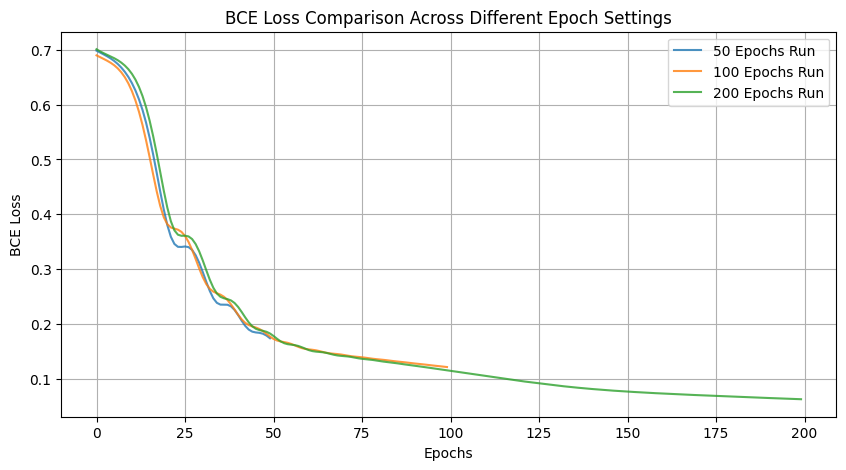

In [7]:
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

# Prepare data
X_train = torch.tensor(X, dtype=torch.float32)
y_train = torch.tensor(y, dtype=torch.float32)
criterion = nn.BCELoss()

def train_rnn(num_epochs):
    # Re-initialize model and optimizer
    model_instance = SimpleRNN()
    optimizer = optim.Adam(model_instance.parameters(), lr=0.01)
    loss_history = []

    # Temporary redirect to suppress intermediate prints from forward pass
    import io
    import sys

    for epoch in range(1, num_epochs + 1):
        model_instance.train()
        optimizer.zero_grad()

        # Silence the print statements inside the forward method
        old_stdout = sys.stdout
        sys.stdout = io.StringIO()
        try:
            predictions = model_instance(X_train)
        finally:
            sys.stdout = old_stdout

        loss = criterion(predictions, y_train)
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())

    # Final metrics
    final_loss = loss_history[-1]
    pred_labels = (predictions >= 0.5).float()
    final_acc = (pred_labels == y_train).float().mean().item() * 100
    print(f"Completed {num_epochs:3d} Epochs | Final Loss: {final_loss:.4f} | Final Accuracy: {final_acc:.2f}%")

    return loss_history

# Train for 50, 100, and 200 epochs
print("Training the RNN under different epochs config:")
loss_50 = train_rnn(50)
loss_100 = train_rnn(100)
loss_200 = train_rnn(200)

# Plotting the comparison curves
plt.figure(figsize=(10, 5))
plt.plot(loss_50, label='50 Epochs Run', alpha=0.8)
plt.plot(loss_100, label='100 Epochs Run', alpha=0.8)
plt.plot(loss_200, label='200 Epochs Run', alpha=0.8)
plt.title('BCE Loss Comparison Across Different Epoch Settings')
plt.xlabel('Epochs')
plt.ylabel('BCE Loss')
plt.legend()
plt.grid(True)
plt.show()

In [8]:
import torch
import pandas as pd

# 1. Instantiate the model and load training settings or use the model_instance
# Since we trained models in the previous cell, let's train a final instance to use for prediction
final_model = SimpleRNN()
optimizer = optim.Adam(final_model.parameters(), lr=0.01)
criterion = nn.BCELoss()

# Silence training output for a quick 200 epochs train
import io, sys
old_stdout = sys.stdout
sys.stdout = io.StringIO()
try:
    for epoch in range(200):
        final_model.train()
        optimizer.zero_grad()
        predictions = final_model(X_train)
        loss = criterion(predictions, y_train)
        loss.backward()
        optimizer.step()
finally:
    sys.stdout = old_stdout

final_model.eval()

# 2. Select 5 test sequences
num_test_samples = 5
with torch.no_grad():
    test_inputs = X_train[:num_test_samples]
    actual_labels = y_train[:num_test_samples].numpy().flatten()

    # Generate predictions
    predicted_probs = final_model(test_inputs).numpy().flatten()
    predicted_labels = (predicted_probs >= 0.5).astype(int)

# 3. Calculate sequence sums and build evaluation table
results = []
for i in range(num_test_samples):
    seq = X[i].flatten()
    seq_sum = seq.sum()
    results.append({
        "Sequence ID": i + 1,
        "Sequence Elements": [round(val, 4) for val in seq],
        "Sequence Sum": round(seq_sum, 4),
        "Actual Label": int(actual_labels[i]),
        "Predicted Probability": round(predicted_probs[i], 4),
        "Predicted Label": int(predicted_labels[i]),
        "Match": "Yes" if int(actual_labels[i]) == int(predicted_labels[i]) else "No"
    })

# Display table
df_results = pd.DataFrame(results)
display(df_results)

,Sequence ID,Sequence Elements,Sequence Sum,Actual Label,Predicted Probability,Predicted Label,Match
0,1,"[0.4967, -0.1383, 0.6477, 1.523, -0.2342]",2.2950,1,0.9986,1,Yes
1,2,"[-0.2341, 1.5792, 0.7674, -0.4695, 0.5426]",2.1856,1,0.9989,1,Yes
2,3,"[-0.4634, -0.4657, 0.242, -1.9133, -1.7249]",-4.3254,0,0.0003,0,Yes
3,4,"[-0.5623, -1.0128, 0.3142, -0.908, -1.4123]",-3.5812,0,0.0003,0,Yes
4,5,"[1.4656, -0.2258, 0.0675, -1.4247, -0.5444]",-0.6617,0,0.1376,0,Yes


In [16]:
import numpy as np
import pandas as pd
import torch

# 1. Generate a large unseen test dataset of 1000 sequences
np.random.seed(999)  # New unseen random seed
X_large_test = np.random.randn(1000, 5, 1)

# 2. Generate actual labels
actual_large_sums = X_large_test.sum(axis=(1, 2))
actual_large_labels = (actual_large_sums > 0).astype(int)

# 3. Predict using our trained final_model
X_large_tensor = torch.tensor(X_large_test, dtype=torch.float32)
final_model.eval()
with torch.no_grad():
    predicted_probs_large = final_model(X_large_tensor).cpu().numpy().flatten()

predicted_labels_large = (predicted_probs_large >= 0.5).astype(int)

# 4. Calculate accuracy
large_accuracy = np.mean(actual_large_labels == predicted_labels_large) * 100
print(f"Evaluated on 1,000 new random sequences:")
print(f"Test Accuracy: {large_accuracy:.2f}%")


Evaluated on 1,000 new random sequences:
Test Accuracy: 97.20%
